In [1]:
display("text/html", "<style>.container { width:100% !important; }</style>")

# Let's take a look at the Pigot data

In [2]:
using DataFrames, CSV, Plots, LaTeXStrings, DelimitedFiles, GLM

In [3]:
Plots.theme(:dao)

In [4]:
include("./diversity-simulator.jl")
using .dsim

In [5]:
pal = cgrad(:tol_muted);
cpal10 = [pal[i] for i in 0.0:1/46:1]

In [6]:
length(cpal10)

47

Import the birds. This is one of many.

In [8]:
read_data = CSV.read("./Pigot2025/Pigot2025/EmpiricalData/Trees_Individual.csv", DataFrame)
gd = groupby(read_data, :Site)

Row,Site,Binomial,Body_Mass,N
,String31,Int64,Float64,Int64
1,1_1_3_200_2018,111,2736.25,1
2,1_1_3_200_2018,121,1782.67,1
3,1_1_3_200_2018,121,950.137,1
4,1_1_3_200_2018,827,527.794,1
5,1_1_3_200_2018,827,154.227,1
6,1_1_3_200_2018,827,528.287,1
7,1_1_3_200_2018,827,177.662,1
8,1_1_3_200_2018,121,1355.73,1
9,1_1_3_200_2018,827,175.706,1


Make a plot of the diversity versus the size.

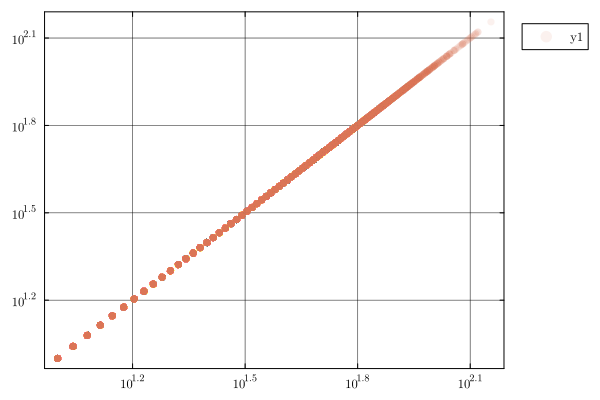

In [9]:
scatter(sum.([x[!,:N] for x in gd]), length.([x[!,:N] for x in gd]), xaxis = :log, yaxis = :log, alpha = 0.1)

In [10]:
logxs = log10.(sum.([x[!,:N] for x in gd]))
logys = log10.(length.([x[!,:N] for x in gd]));

In [11]:
df = DataFrame(y = logys, x = logxs);

In [12]:
glm = lm(@formula(y ~ x), df)

StatsModels.TableRegressionModel{LinearModel{GLM.LmResp{Vector{Float64}}, GLM.DensePredChol{Float64, LinearAlgebra.CholeskyPivoted{Float64, Matrix{Float64}, Vector{Int64}}}}, Matrix{Float64}}

y ~ 1 + x

Coefficients:
──────────────────────────────────────────────────────────────────────────────────────────────
                   Coef.   Std. Error                    t  Pr(>|t|)    Lower 95%    Upper 95%
──────────────────────────────────────────────────────────────────────────────────────────────
(Intercept)  3.83609e-14  2.0442e-16                187.66    <1e-99  3.79602e-14  3.87616e-14
x            1.0          1.45529e-16  6871475867841377.00    <1e-99  1.0          1.0
──────────────────────────────────────────────────────────────────────────────────────────────

In [13]:
coef(glm)

2-element Vector{Float64}:
 3.836089781575088e-14
 0.9999999999999714

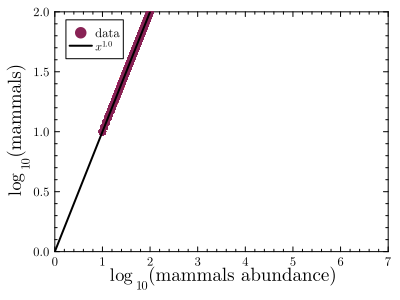

In [14]:
scatter(log10.(sum.([x[!,:N] for x in gd])), log10.(length.([x[!,:N] for x in gd])), alpha = 1.0, label = "data", c = pal[8]);
plot!(collect(0:7),coef(glm)[1] .+ collect(0:7) .*coef(glm)[2], label = L"x^{%$(round(coef(glm)[2],digits = 2))}", color = :black, lw = 2)
plot!(xlims = [0,7], ylims = [0,2], ylabel = L"$\log_{10}$(mammals)", xlabel = L"$\log_{10}$(mammals abundance)", legend = :topleft,
    size = (400,300), grid = :none, minorgrid = :none)

Now let's make the rank-frequency plots.

In [18]:
si = sortperm(length.([x[!,:N] for x in gd]), rev = true);

In [19]:
cpal = [pal[i] for i in 0.0:1/length(gd):1];

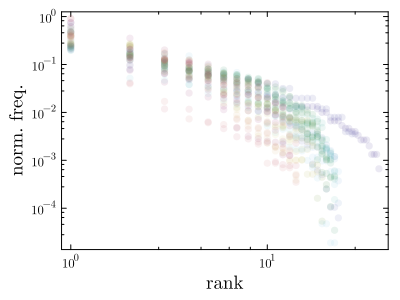

In [20]:
scatter(sort(gd[si[1]][!,:N]./sum(gd[si[1]][!,:N]), rev = true), xaxis = :log, yaxis = :log, color = cpal[1], alpha = 0.1)
for i in 2:length(gd)
    scatter!(sort(gd[si[i]][!,:N]./sum(gd[si[i]][!,:N]), rev = true), color = cpal[i], alpha = 0.1)
end
scatter!(legend = :none, ylabel = "norm. freq.", xlabel = "rank", size = (400,300), grid = :none, minorgrid = :none)